In [45]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.datasets import load_wine
from sklearn.metrics import accuracy_score, confusion_matrix, recall_score, f1_score, classification_report
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline

In [46]:
# Training & Prediction Process (sklearn view)
wine= load_wine()
X= wine.data
y=wine.target

print('Dataset shape:',X.shape)
print('Class:', list(wine.target_names))

#train test
X_train, X_test, y_train, y_test= train_test_split( X, y, test_size=0.25, random_state=42, stratify=y)

Dataset shape: (178, 13)
Class: [np.str_('class_0'), np.str_('class_1'), np.str_('class_2')]


In [47]:
# Baseline KNN model (Euclidean distance via Minkowski p=2)
clf= Pipeline([
    ('scaler', StandardScaler()),
    ('knn', KNeighborsClassifier(n_neighbors=14,  metric='minkowski', p=2 ))
])

clf.fit(X_train,y_train)
y_pred=clf.predict(X_test)

In [48]:
print("Accuracy:", float(accuracy_score(y_test, y_pred)))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred,target_names=wine.target_names))

Accuracy: 0.9777777777777777

Confusion Matrix:
 [[15  0  0]
 [ 1 17  0]
 [ 0  0 12]]

Classification Report:
               precision    recall  f1-score   support

     class_0       0.94      1.00      0.97        15
     class_1       1.00      0.94      0.97        18
     class_2       1.00      1.00      1.00        12

    accuracy                           0.98        45
   macro avg       0.98      0.98      0.98        45
weighted avg       0.98      0.98      0.98        45



2- Model Evaluation & Optimization

In [49]:
#We will tune K by trying a range of values and plotting accuracy.
k_value=range(1,45)
accs=[]

for k in k_value:
  model=Pipeline([
      ('scaler', StandardScaler()),
      ('knn', KNeighborsClassifier( n_neighbors=k ))
  ])

  model.fit(X_train, y_train)
  pred = model.predict(X_test)
  accs.append(accuracy_score(y_test, pred))


In [50]:
  print(accs)

[0.9555555555555556, 0.9333333333333333, 0.9555555555555556, 0.9333333333333333, 0.9333333333333333, 0.9333333333333333, 0.9777777777777777, 0.9555555555555556, 0.9777777777777777, 0.9777777777777777, 0.9777777777777777, 0.9777777777777777, 0.9777777777777777, 0.9777777777777777, 1.0, 0.9777777777777777, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 0.9777777777777777, 0.9777777777777777, 0.9555555555555556, 0.9555555555555556, 0.9555555555555556, 0.9777777777777777, 0.9555555555555556, 0.9555555555555556, 0.9555555555555556, 0.9555555555555556, 0.9111111111111111, 0.9333333333333333, 0.9111111111111111, 0.9111111111111111, 0.9111111111111111, 0.9555555555555556, 0.9111111111111111, 0.9333333333333333, 0.9333333333333333, 0.9111111111111111, 0.9111111111111111]


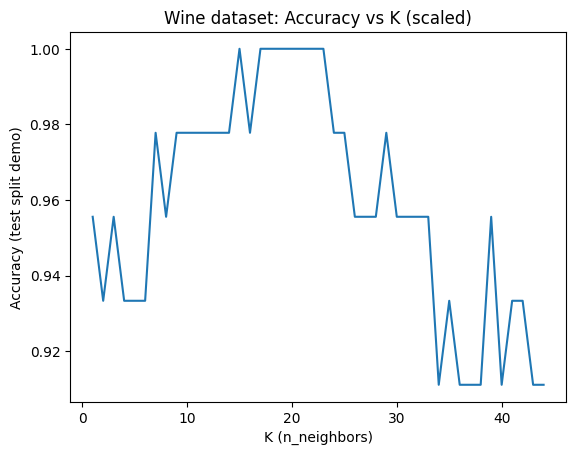

Best K (by this demo): 15
Best accuracy: 1.0


In [51]:
plt.figure()
plt.plot(list(k_value),accs)
plt.xlabel("K (n_neighbors)")
plt.ylabel("Accuracy (test split demo)")
plt.title("Wine dataset: Accuracy vs K (scaled)")
plt.show()

best_k = list(k_value)[int(np.argmax(accs))]
print("Best K (by this demo):", best_k)
print("Best accuracy:", float(np.max(accs)))

In [52]:
#Compare distance metrics and voting weights
k_demo= best_k
settings=[
    ('Euclidean (p=2), uniform', KNeighborsClassifier(n_neighbors=k_demo, metric='minkowski',p=2, weights='uniform')),
    ('Manhattan (p=1), uniform', KNeighborsClassifier(n_neighbors=k_demo, metric='minkowski',p=1, weights='uniform')),
    ('Euclidean (p=2), distance', KNeighborsClassifier(n_neighbors=k_demo, metric='minkowski',p=2, weights='distance')),
]

rows=[]
for name,knn in settings:
  model.fit(X_train, y_train)
  pred = model.predict(X_test)
  rows.append([name,accuracy_score(y_test,pred)])

pd.DataFrame(rows, columns=["Setting","Accuracy"]).sort_values("Accuracy", ascending=False)

,Setting,Accuracy
0,"Euclidean (p=2), uniform",0.911111
1,"Manhattan (p=1), uniform",0.911111
2,"Euclidean (p=2), distance",0.911111


In [53]:
#KNN without scaling(intentionally)
knn_no_scale = KNeighborsClassifier(n_neighbors=best_k)
knn_no_scale.fit(X_train, y_train)
pred_no_scale = knn_no_scale.predict(X_test)
acc_no_scale = accuracy_score(y_test, pred_no_scale)

#KNN with scaling(pipeline)
pred_scaled = clf.predict(X_test)
acc_scaled = accuracy_score(y_test, pred_scaled)
print("Accuracy without scaling:", float(acc_no_scale))
print("Accuracy with scaling:", float(acc_scaled))


Accuracy without scaling: 0.7777777777777778
Accuracy with scaling: 0.9777777777777777
